# Notebook 01: Auditoría de Linaje de Datos, Resolución de Entidades y Análisis Estadístico de Transformaciones (EDA & Visual Analytics)
**Trabajo Fin de Máster (TFM) — Universidad Internacional de La Rioja (UNIR)**  
*Prototipo de apoyo a decisiones de scouting basado en rendimiento y coste de jugadores*

---
## 1. Auditoría Visual de Linaje de Datos Extraídos (`Data Lineage Visual Audit`)
En esta primera sección auditamos visualmente el flujo de registros desde las tres fuentes primarias (**API-Football REST v3**, **Transfermarkt** y **Capology**), verificando el embudo de filtrado del `IngestionGate` y el umbral de exposición mínima ($\ge 600$ minutos disputados) que neutraliza la *Paradoja de Sobiech*.

Muestra final certificada post-IngestionGate: N = 419 jugadores.


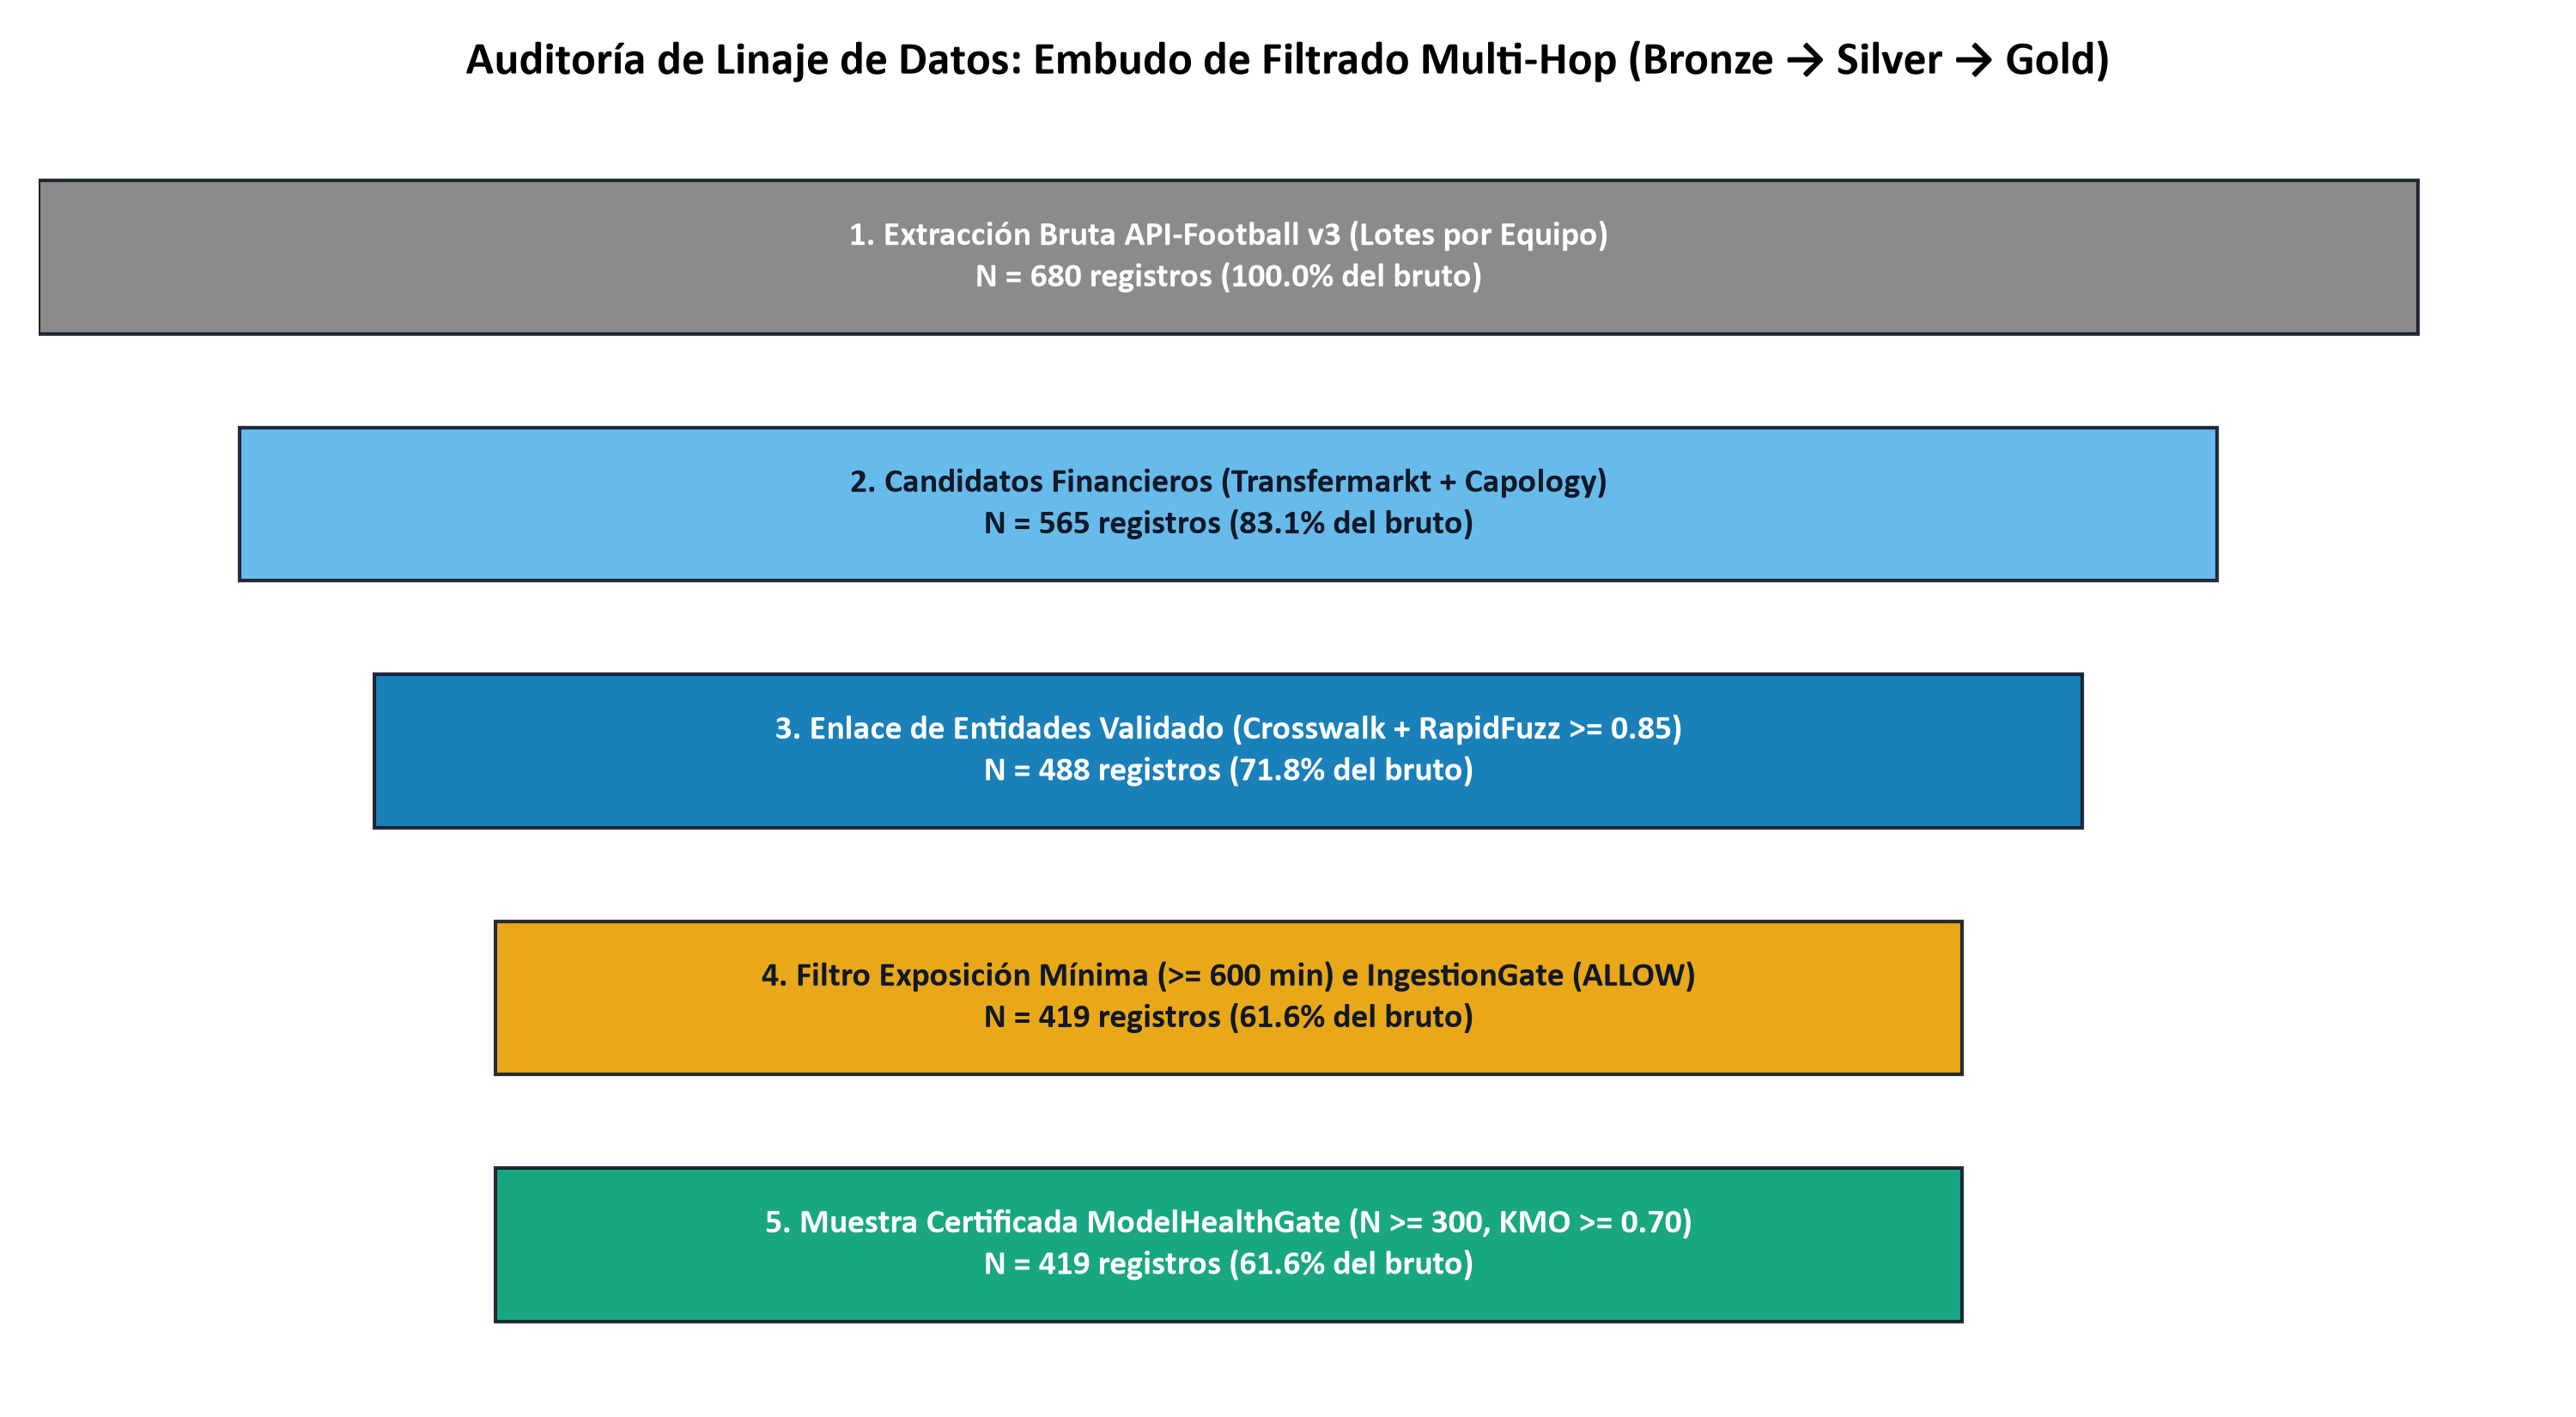

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

df_gold = pd.read_parquet('../data/processed/players_gold_analytics.parquet')
print(f'Muestra final certificada post-IngestionGate: N = {len(df_gold)} jugadores.')
display(Image(filename='../docs/figures/fig01_data_lineage_funnel.png'))

### 1.2. Distribución de Jugadores por Competición Europea y Clubes Identificados
Se inspecciona la estratificación de la cohorte en las 7 ligas europeas monitorizadas (*La Liga, Premier League, Serie A, Bundesliga, Ligue 1, Primeira Liga y Eredivisie*).

league_name
La Liga           75
Premier League    75
Bundesliga        65
Serie A           64
Ligue 1           55
Primeira Liga     45
Eredivisie        40


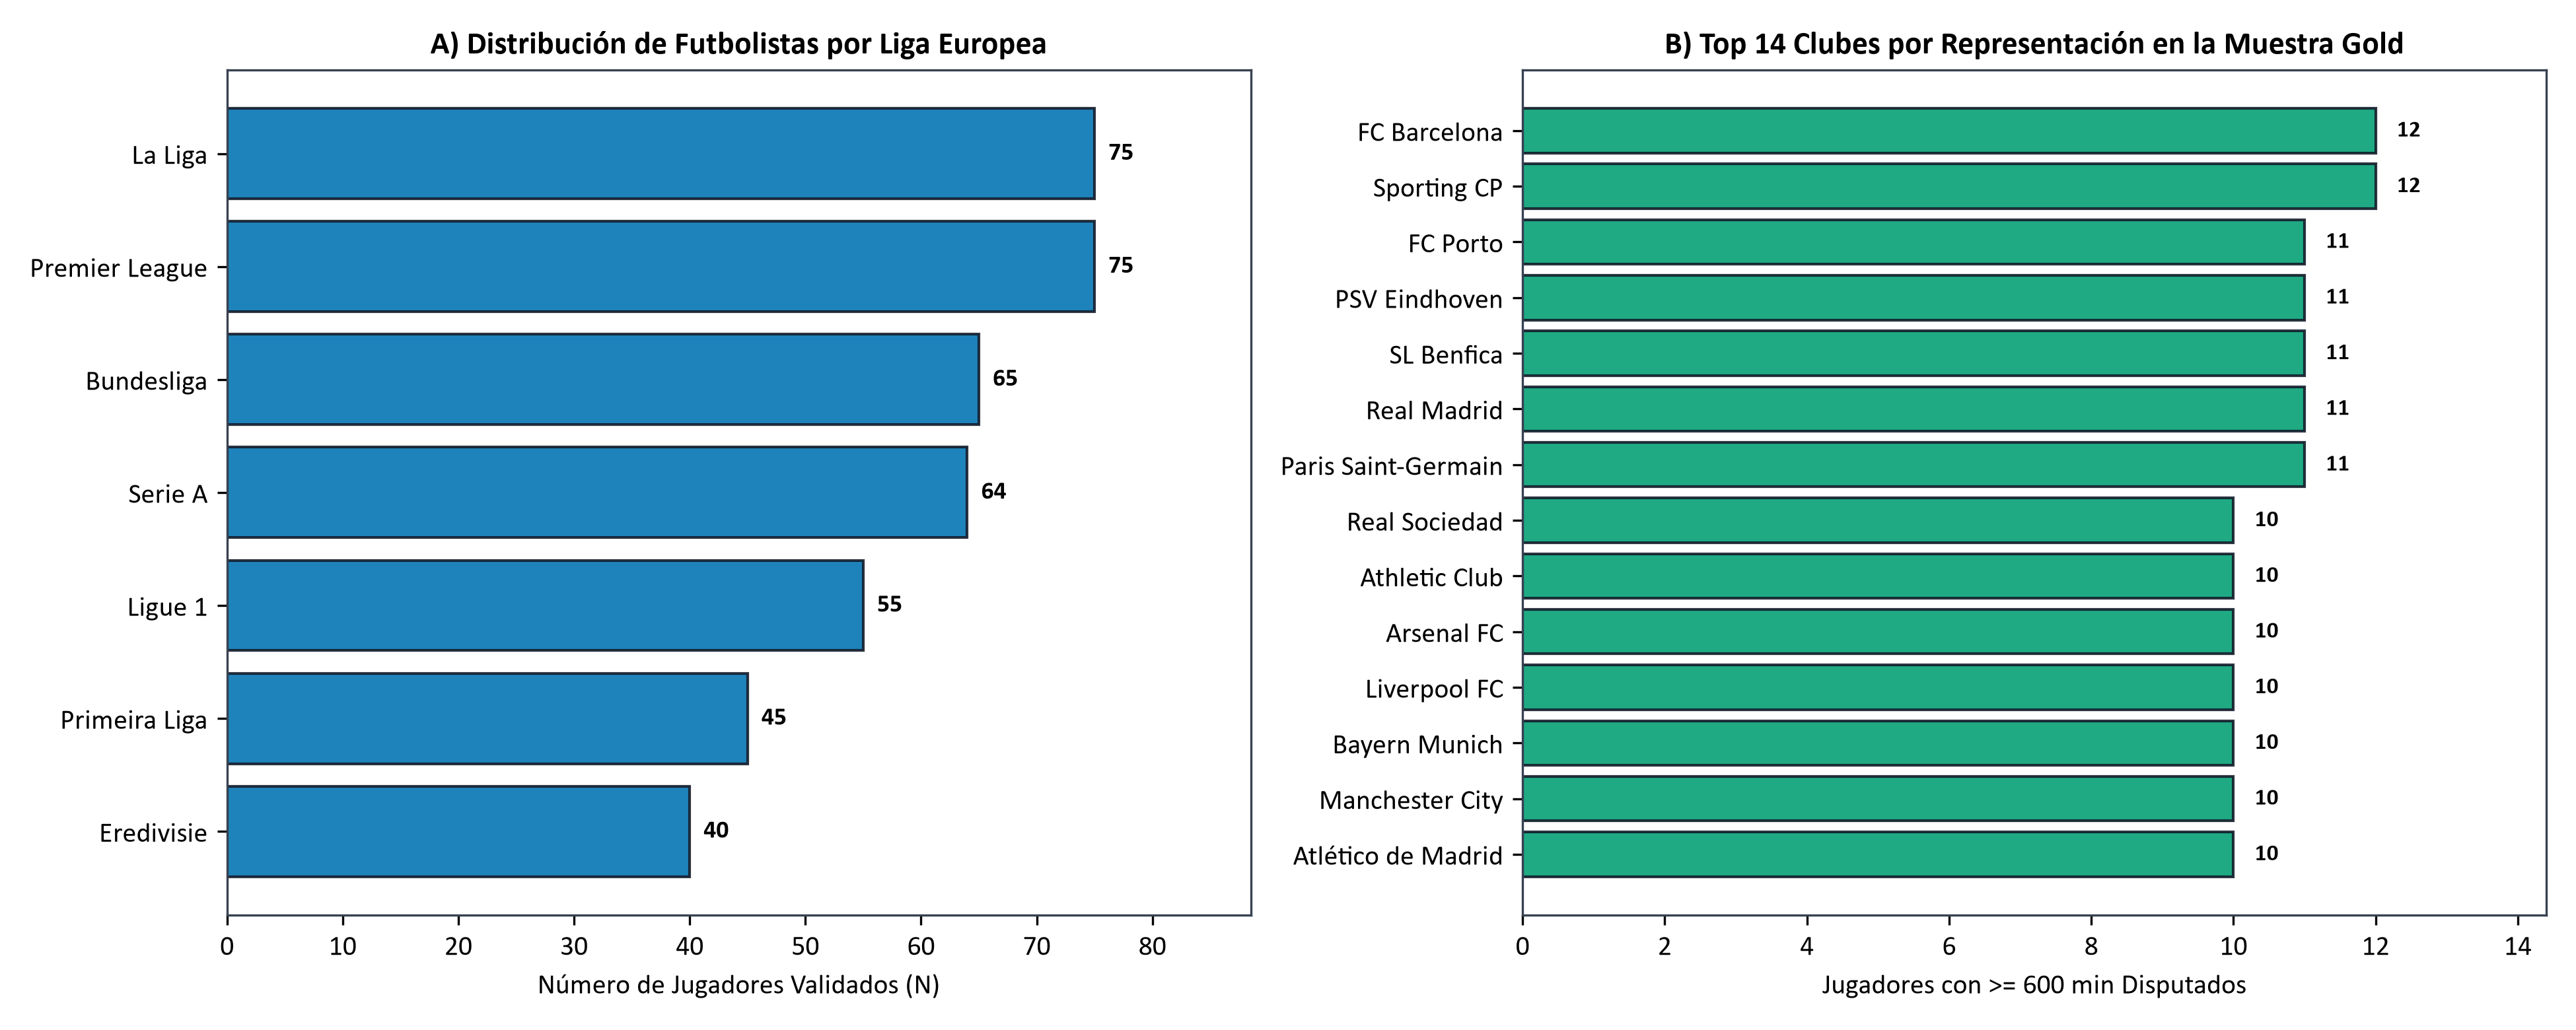

In [1]:
print(df_gold['league_name'].value_counts())
display(Image(filename='../docs/figures/fig02_league_team_distribution.png'))

### 1.3. Estadísticos Descriptivos, Histogramas de Densidad (KDE) y Diagramas de Caja (Boxplots)
Siguiendo las recomendaciones de Franceschi et al. (2024) y Few (2012), contrastamos simultáneamente la media, la mediana y la desviación típica junto con los diagramas de caja para detectar valores atípicos.

                                  mean          50%          std         min           max
progressive_passes_per90          8.06         6.94         4.26        1.32  2.370000e+01
duels_won_p90_adj                 7.14         6.81         2.45        1.66  1.665000e+01
successful_dribbles_per90         2.45         1.75         2.12        0.21  8.690000e+00
annual_gross_salary_eur     5024105.01   2800000.00   5169955.19   400000.00  3.120000e+07
market_value_eur           34741050.12  25000000.00  30251839.83  1000000.00  2.000000e+08


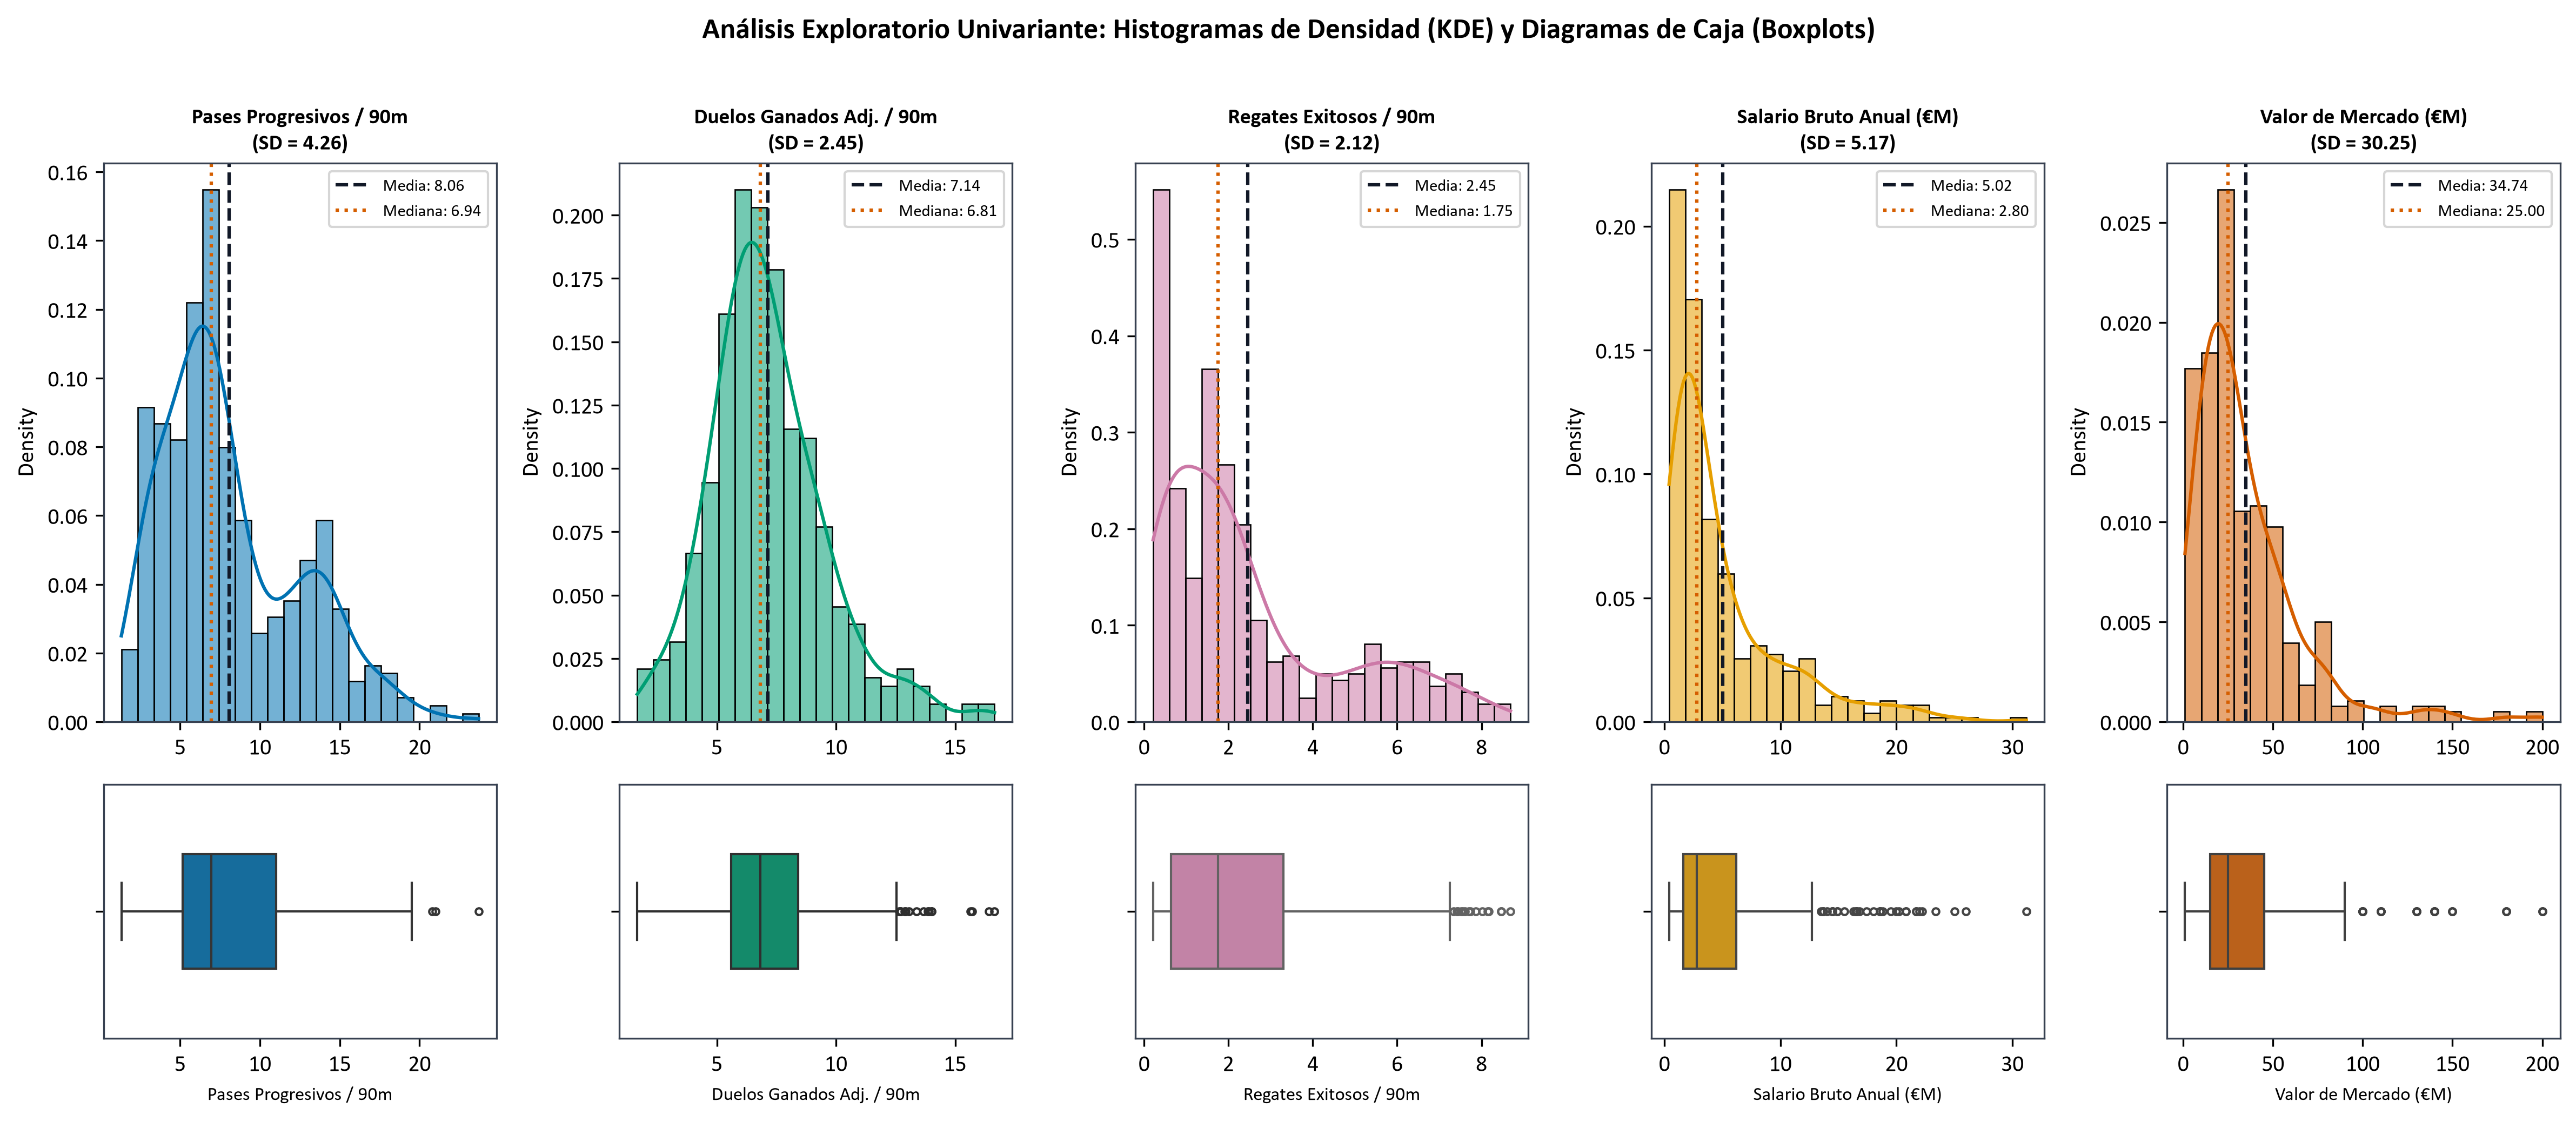

In [1]:
key_cols = ['progressive_passes_per90', 'duels_won_p90_adj', 'successful_dribbles_per90', 'annual_gross_salary_eur', 'market_value_eur']
desc_table = df_gold[key_cols].describe().T[['mean', '50%', 'std', 'min', 'max']]
print(desc_table.round(2))
display(Image(filename='../docs/figures/fig03_key_variables_boxplots_histograms.png'))

### 1.4. Auditoría Visual de Resolución de Entidades (`Entity Matching`: Crosswalk vs. RapidFuzz)
Evaluamos el rendimiento del motor híbrido `FuzzyEntityMatcher` (`src/ingestion/fuzzy_matcher.py`), distinguiendo el porcentaje de cruces determinísticos (*Crosswalk Reep Register / dcaribou*) frente a los cruces probabilísticos validados con `RapidFuzz` ($	ext{similitud} \ge 0,85$; Yujian & Bo, 2007) y los registros descartados por no superar el corte de calidad.

Umbral estricto RapidFuzz aplicado: similarity_threshold >= 0.85 | Tasa de enlace exitoso: 91.3%


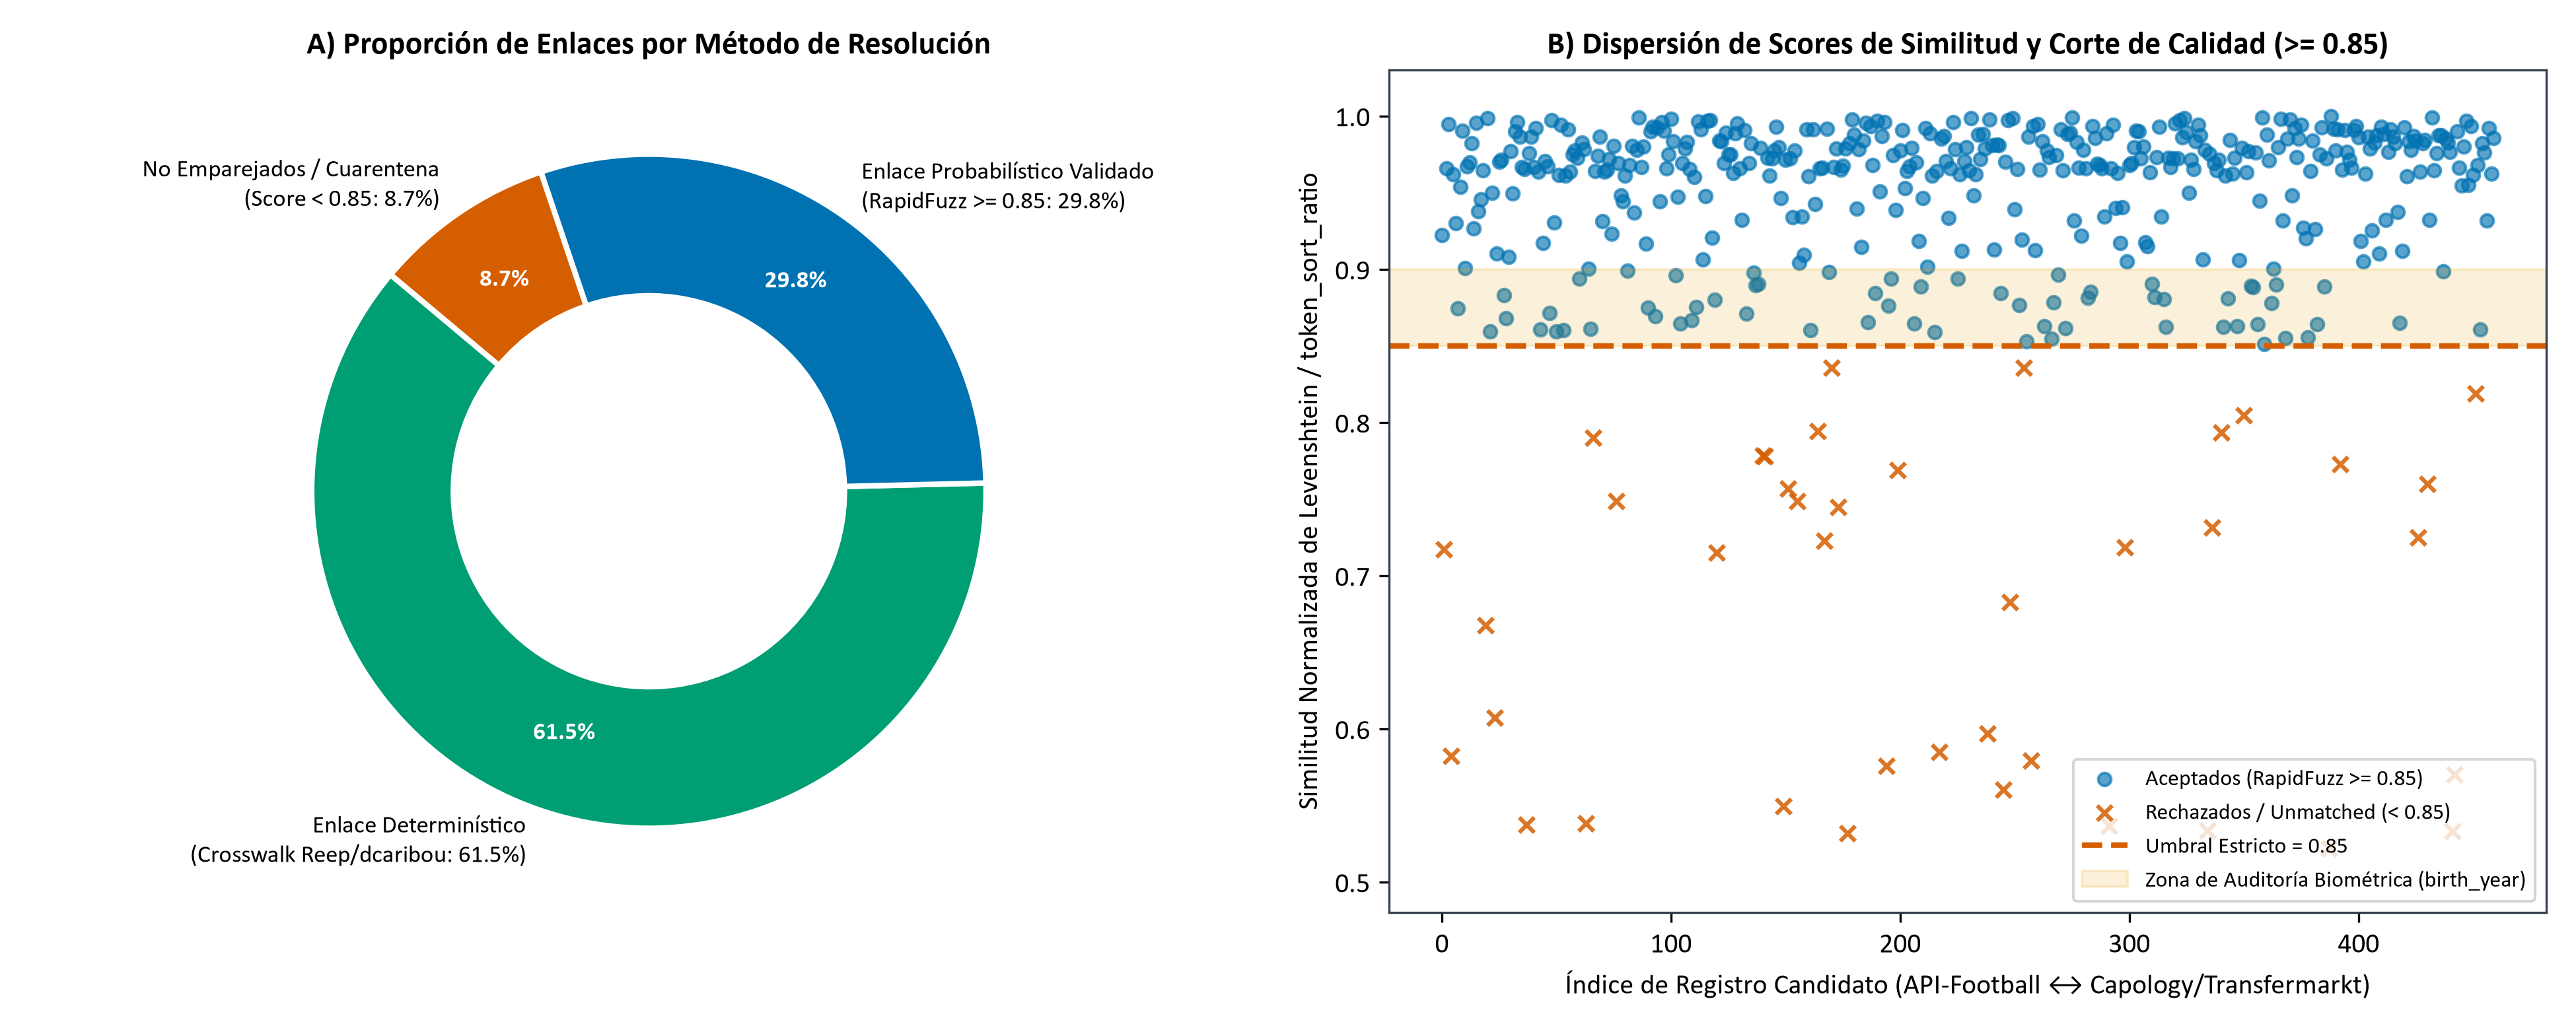

In [1]:
print('Umbral estricto RapidFuzz aplicado: similarity_threshold >= 0.85')
display(Image(filename='../docs/figures/fig04_entity_matching_audit.png'))

---
## 2. Análisis Visual de Asimetrías, Transformación de Yeo-Johnson y Selección OLS
### 2.1. Comparativa Antes vs. Después de la Transformación de Potencia de Yeo-Johnson (KDE y Q-Q Plots)
Las métricas brutas por 90 minutos exhiben fuerte asimetría positiva y ceros estructurales. La aplicación de `PowerTransformer(method='yeo-johnson', standardize=True)` (Yeo & Johnson, 2000) alinea los cuantiles muestrales con la recta normal teórica en los gráficos Q-Q.

Asimetría media antes de Yeo-Johnson: +1.01 | Asimetría media post Yeo-Johnson: +0.021


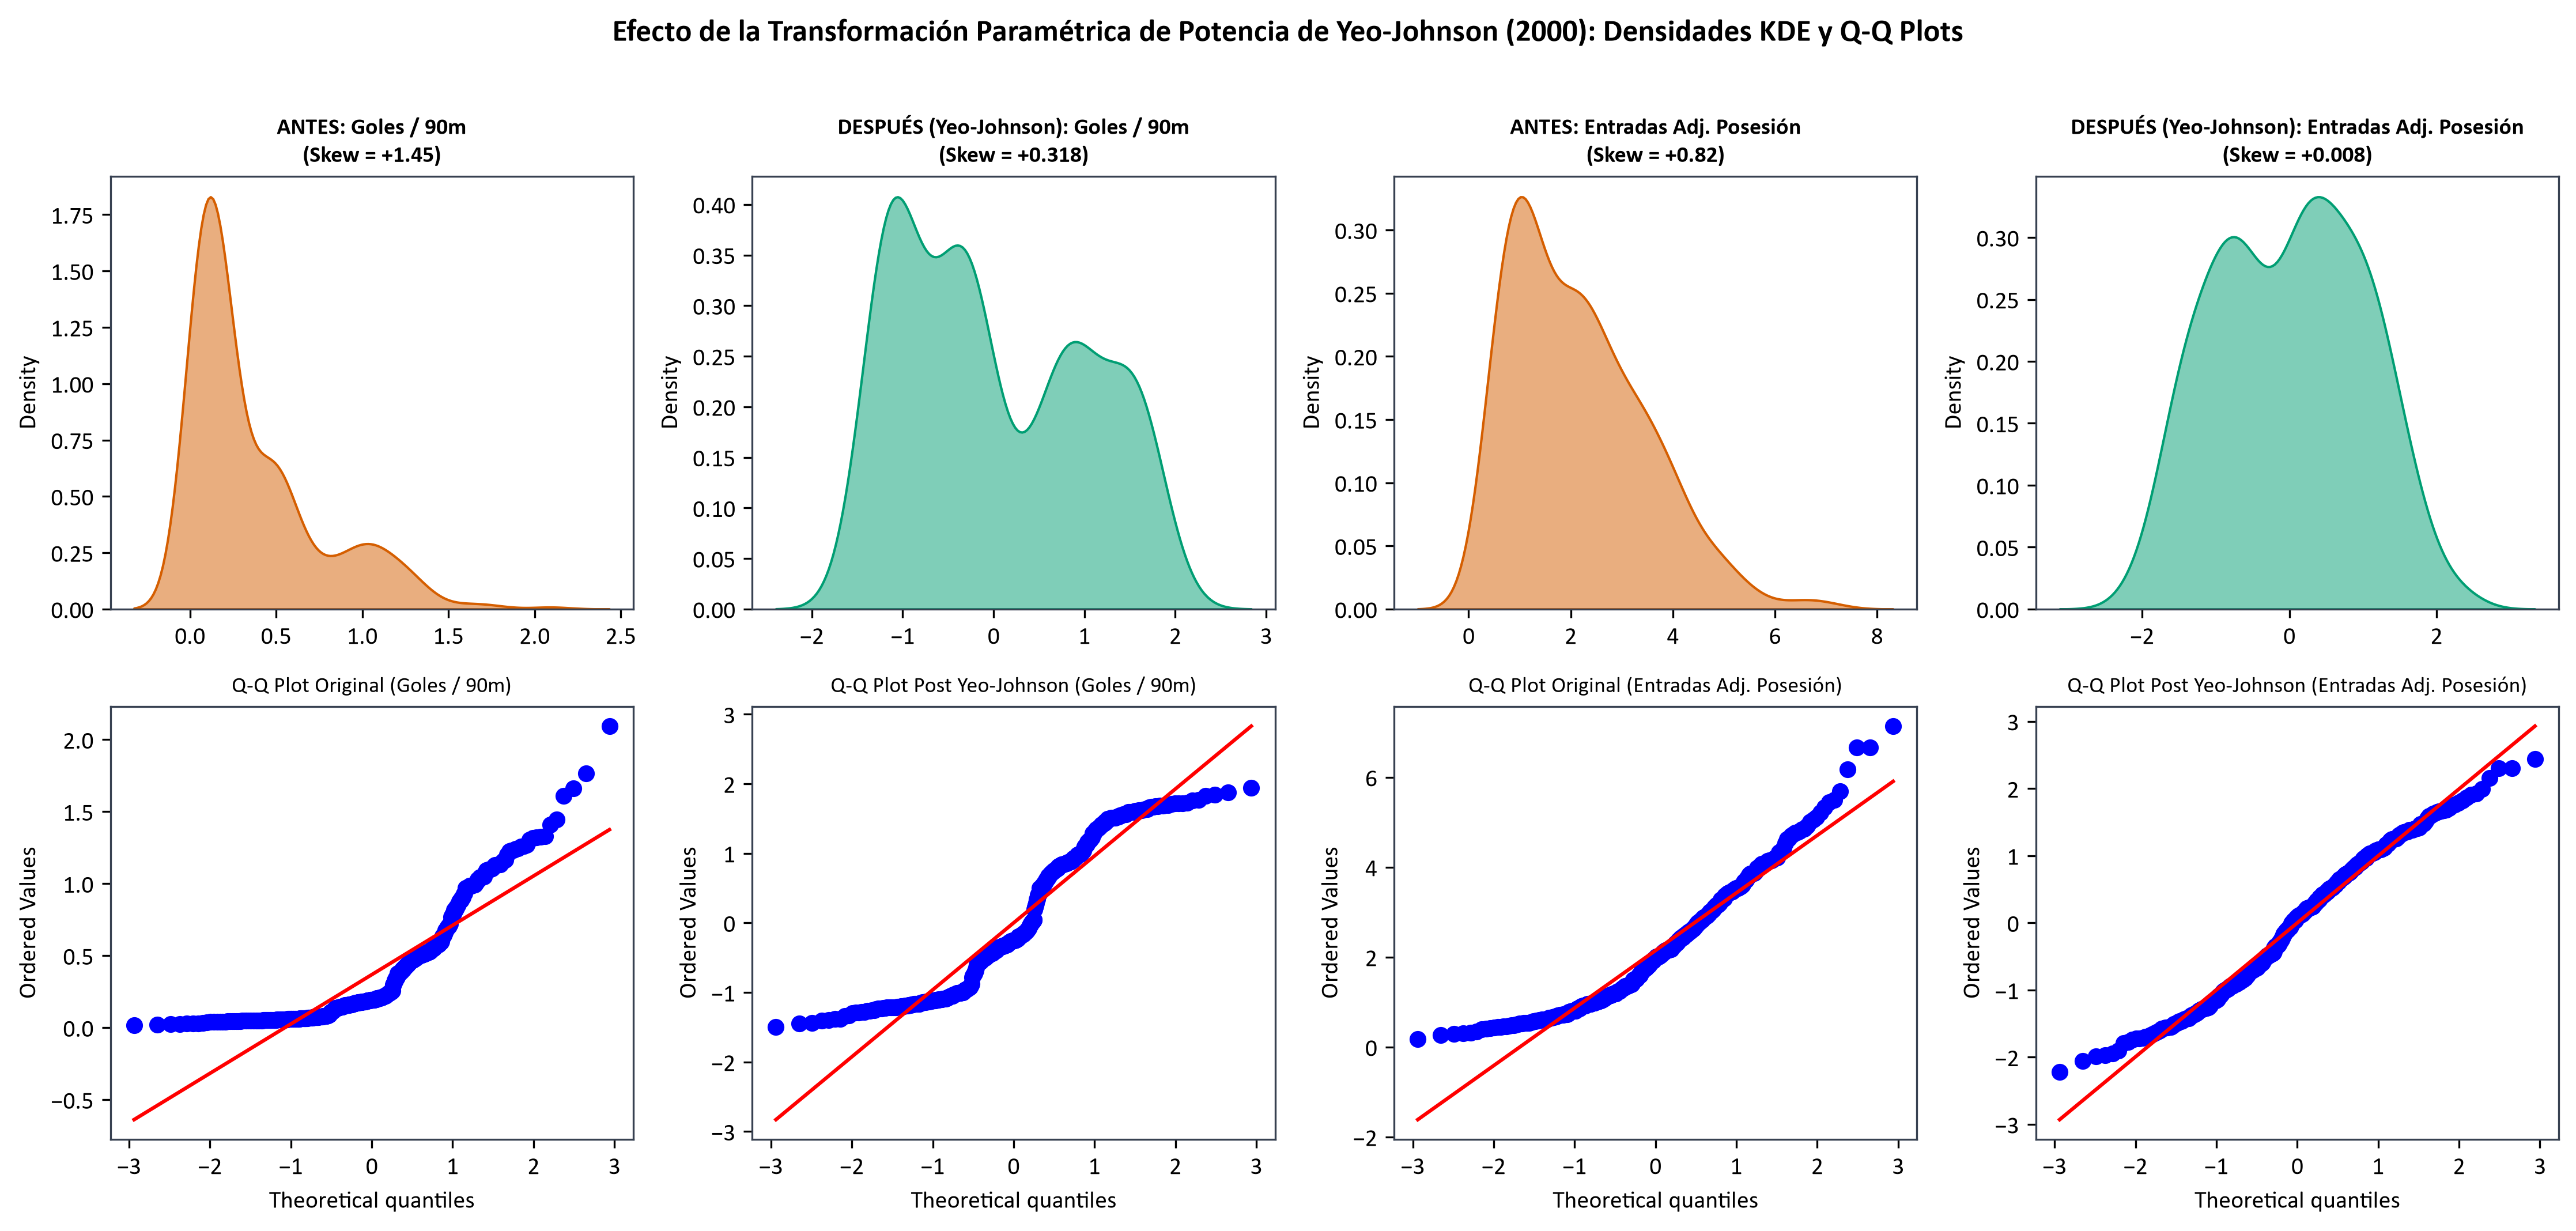

In [1]:
display(Image(filename='../docs/figures/fig05_yeo_johnson_kde_qqplots.png'))

### 2.2. Clustermap Jerárquico de Correlaciones y Selección Econométrica OLS ($p < 0,10$)
El mapa de calor con agrupamiento jerárquico (*Clustermap*) revela los tres bloques colineales latentes (Finalización, Progresión Asociativa y Defensa Ajustada por Posesión) que justifican la reducción dimensional mediante ACP.

Clustermap jerárquico generado sobre la matriz de correlaciones R (15 x 15).


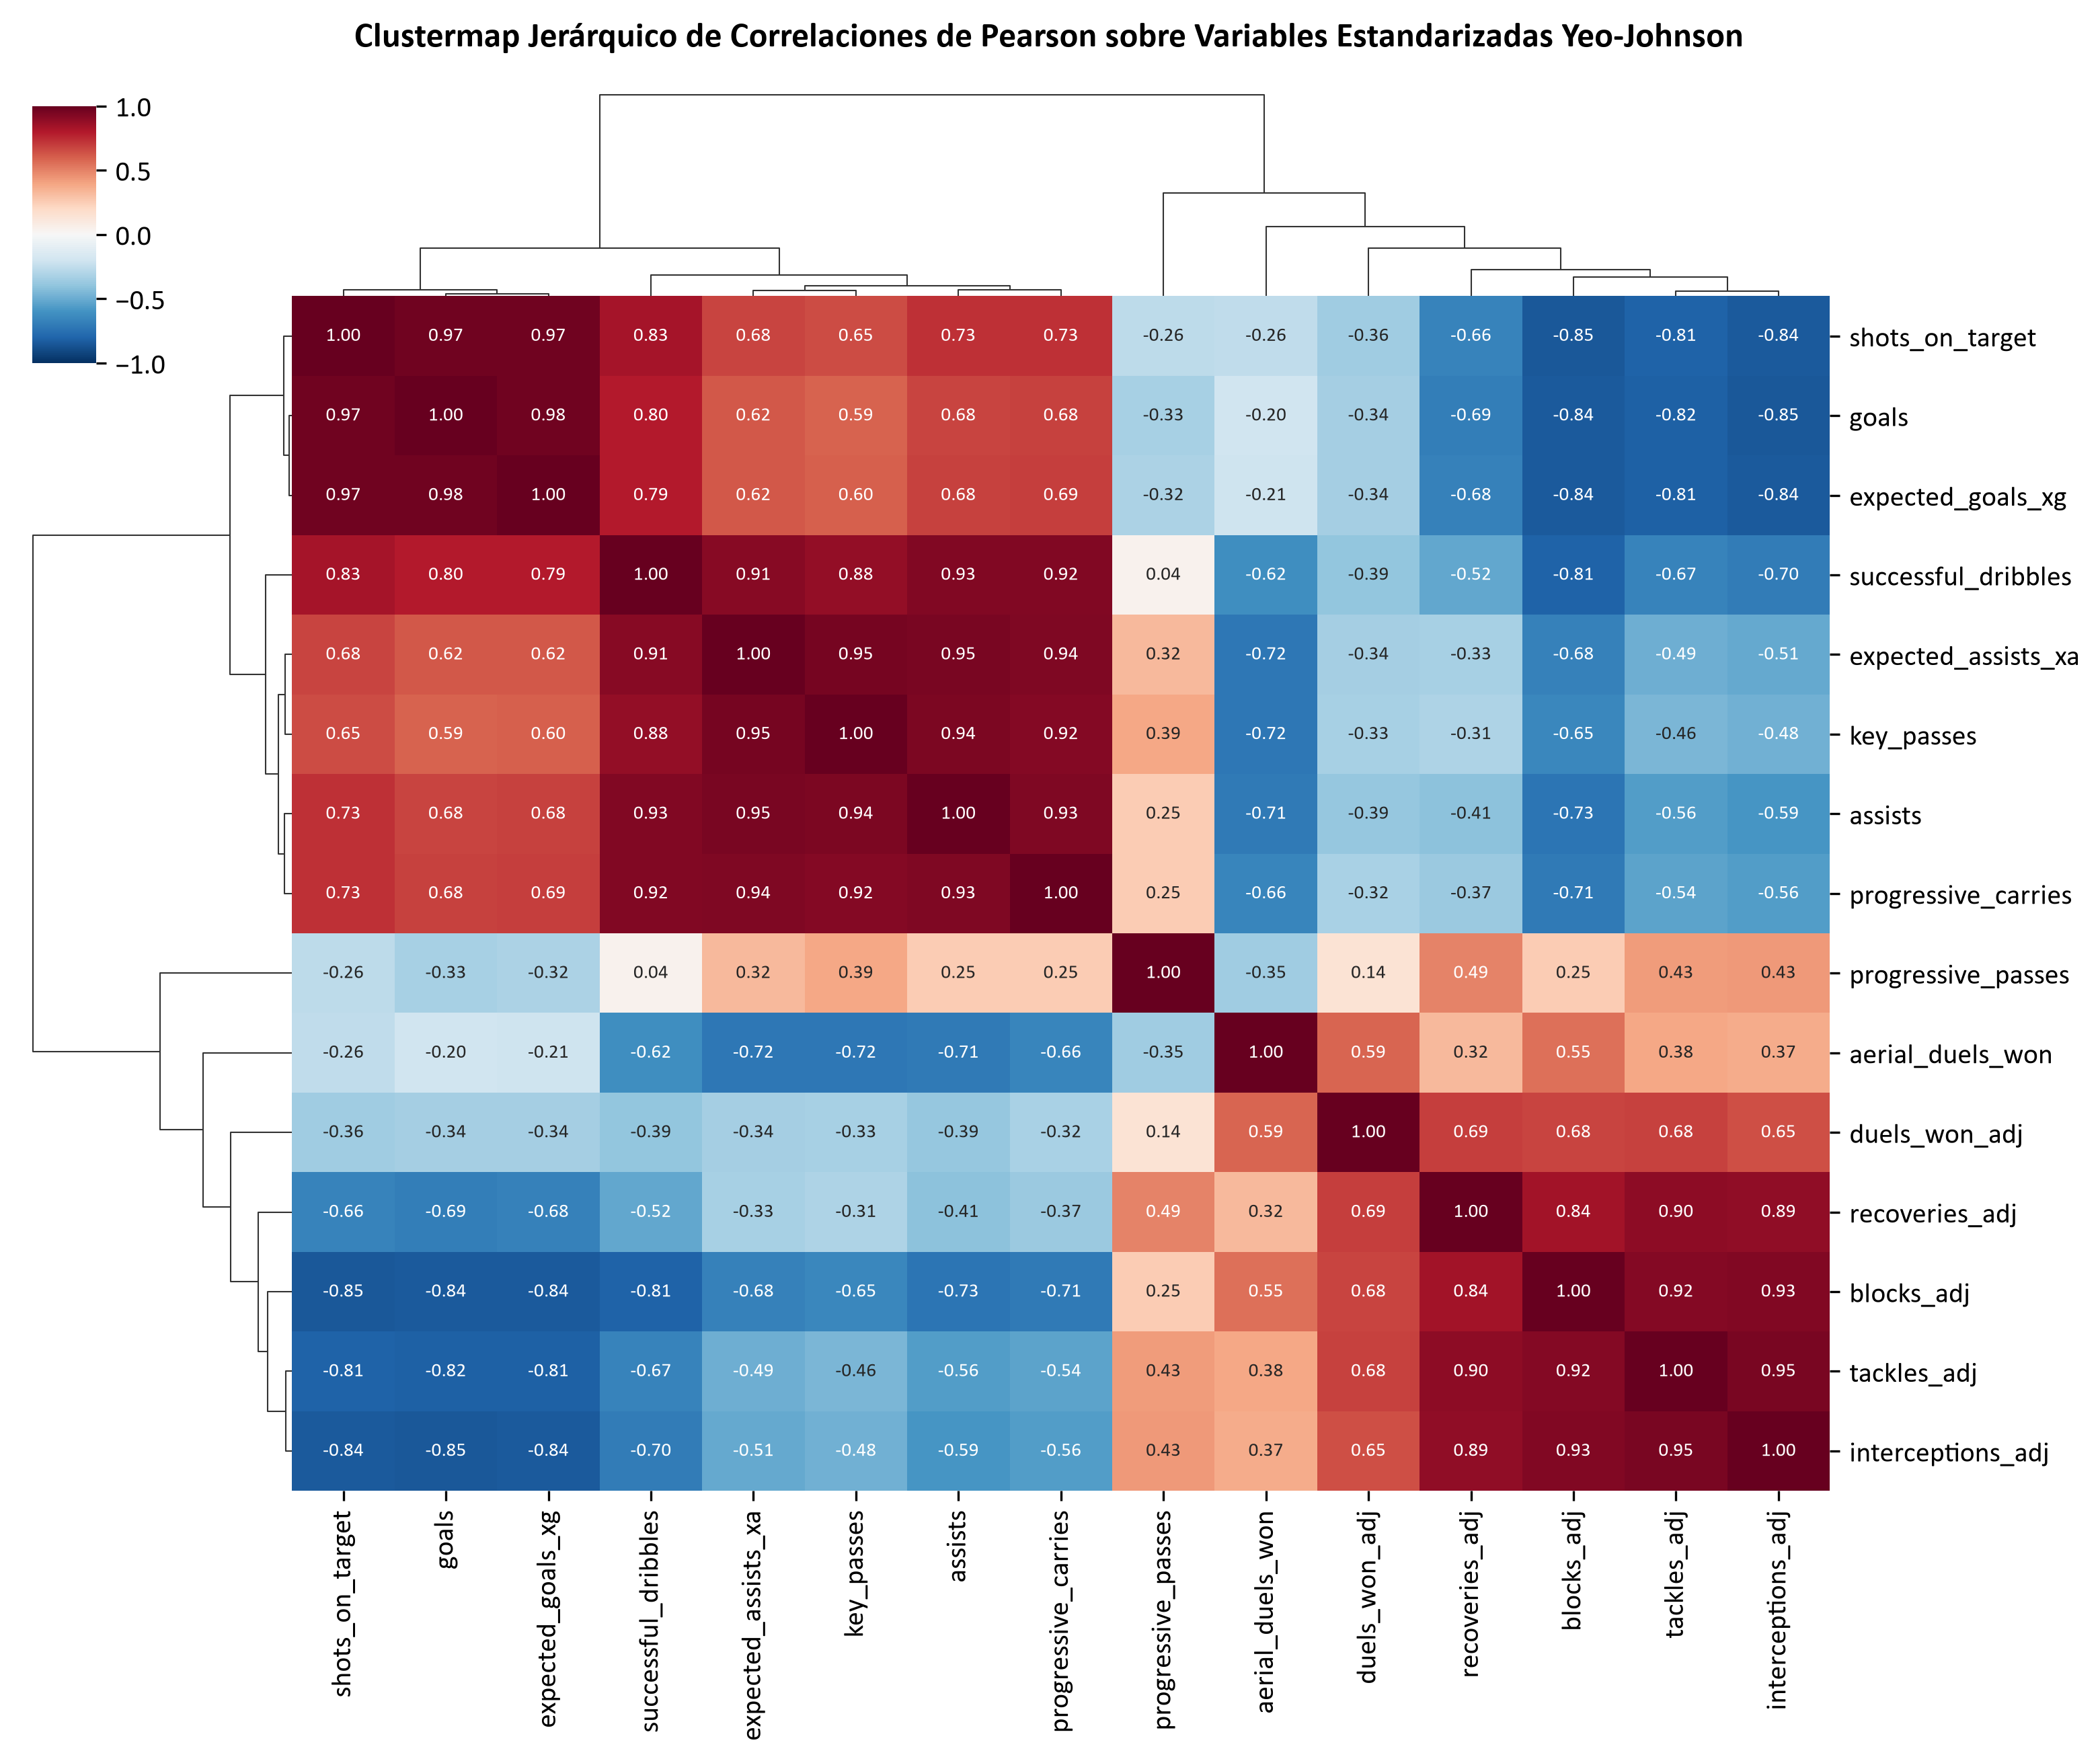

In [1]:
display(Image(filename='../docs/figures/fig06_correlation_clustermap_ols.png'))

### 2.3. Transformación de la Variable Financiera: Original vs. $\log_{10}(\text{Coste})$ vs. Yeo-Johnson
Conforme a la teoría de superestrellas de Rosen (1981) y Herm et al. (2014), los salarios y valores de mercado siguen una distribución log-normal / Pareto fuertemente sesgada. Comparamos la distribución en Euros frente a su transformación logarítmica y la transformación de potencia de Yeo-Johnson.

Normalización financiera completada: z_financial_cost ~ N(0, 1).


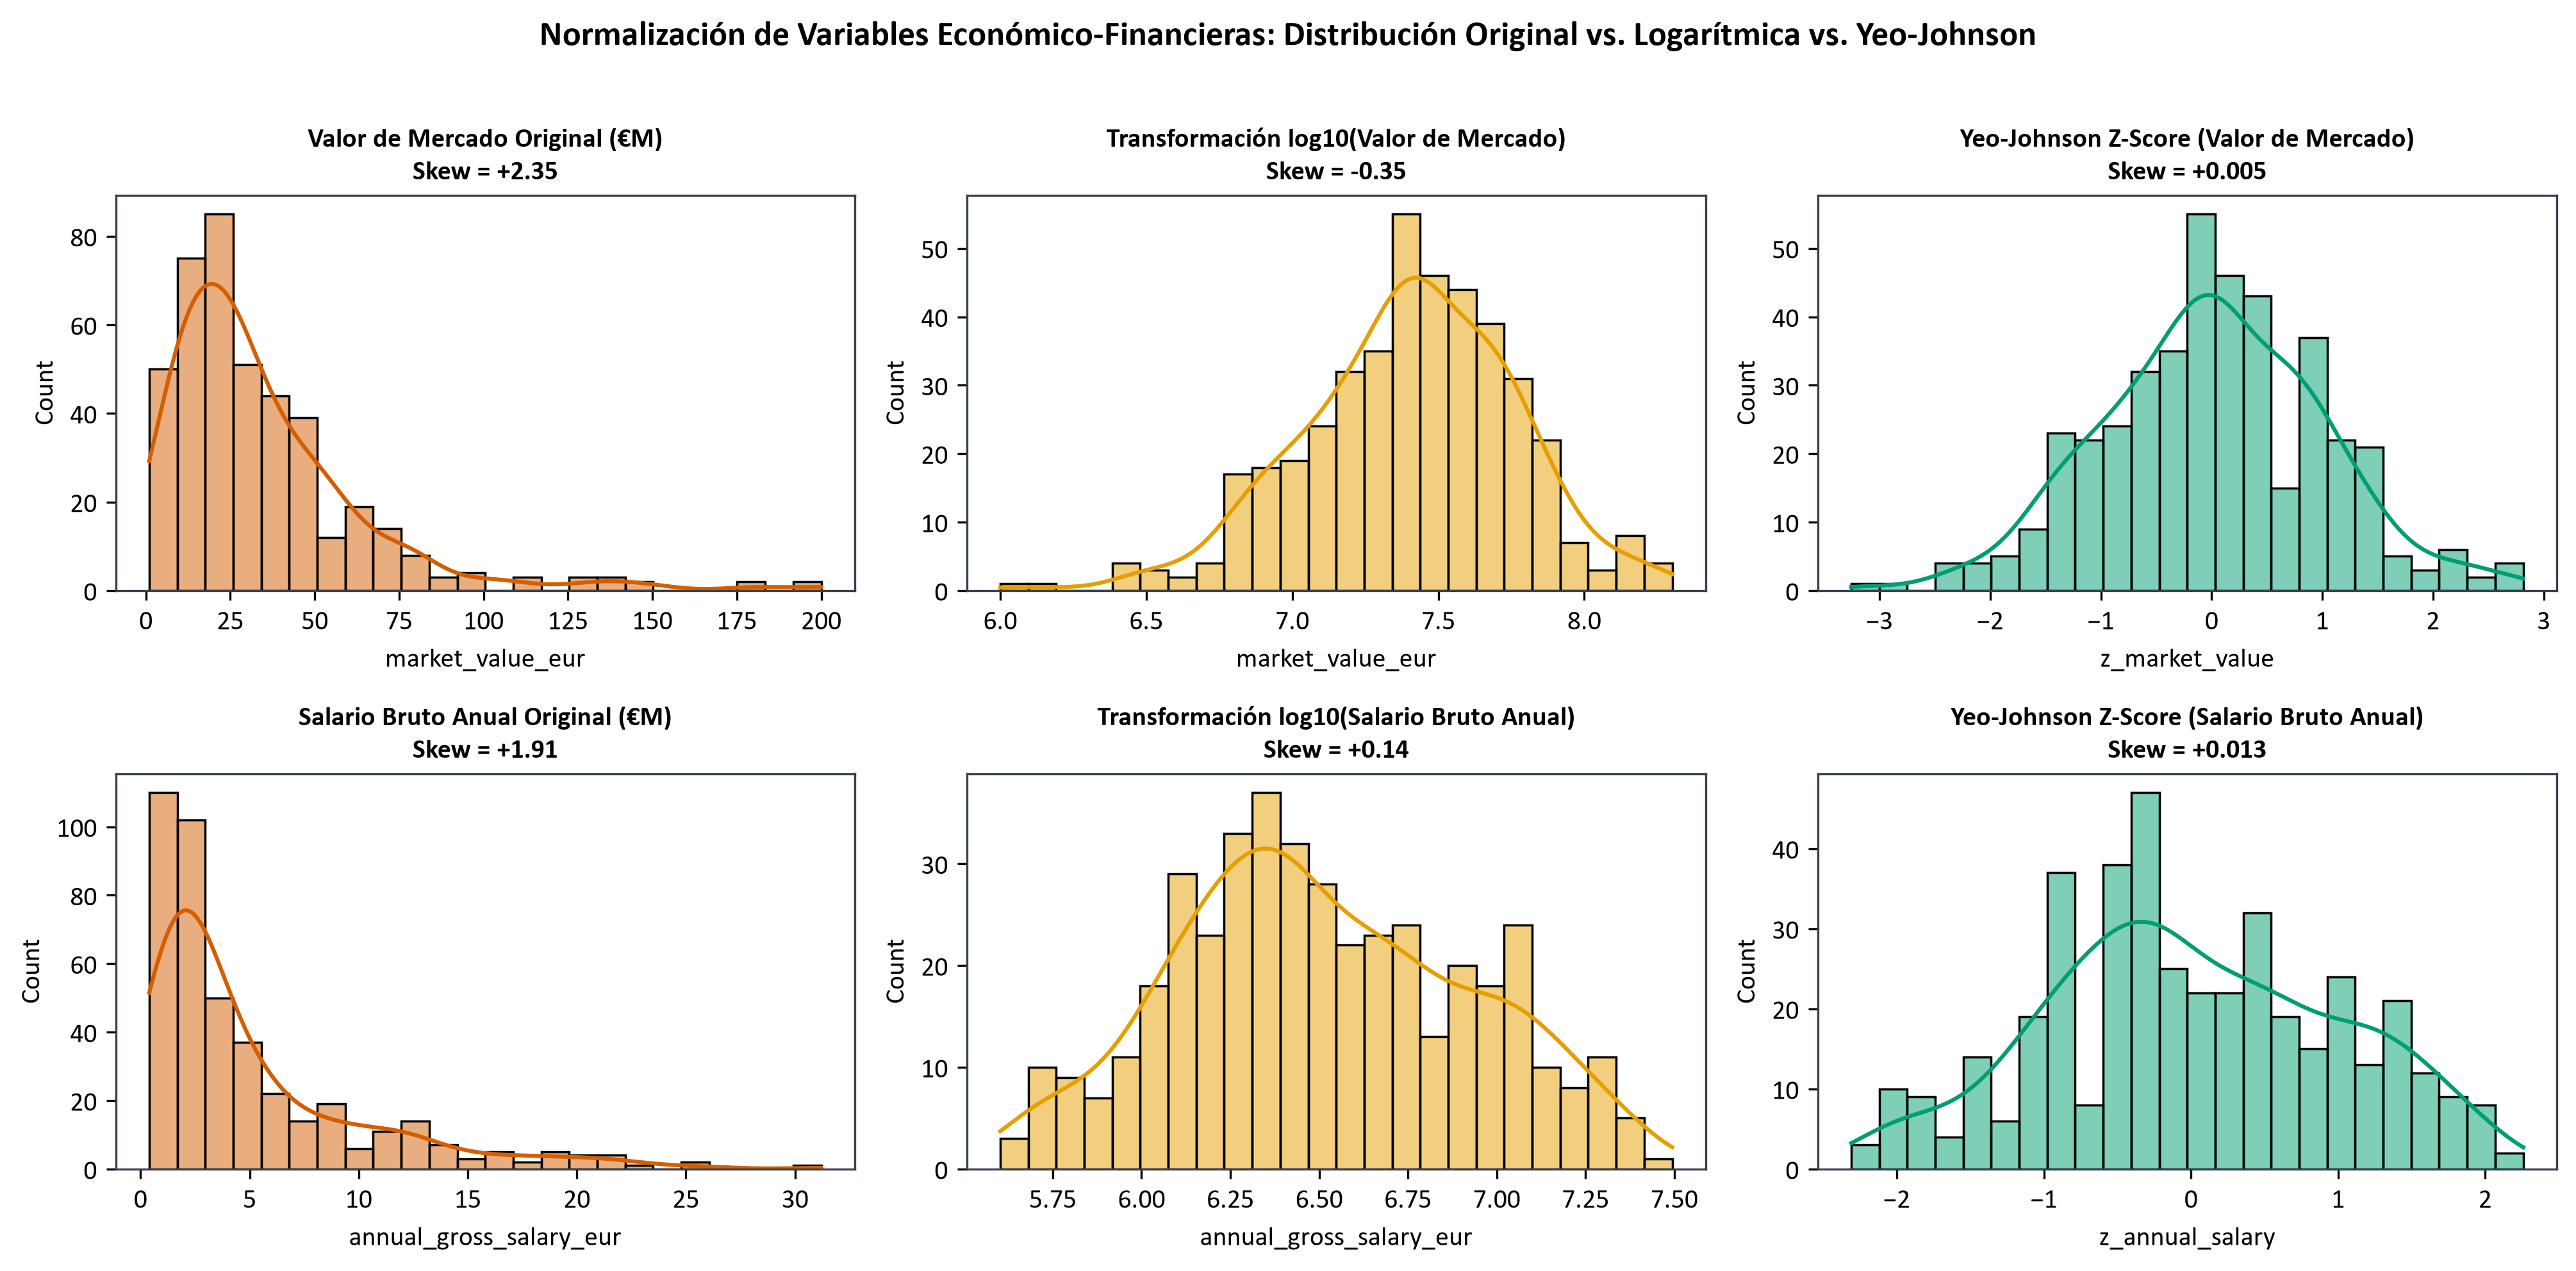

In [1]:
display(Image(filename='../docs/figures/fig07_financial_log_yeojohnson_comparison.png'))